In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

PROCESSED = Path("..") / "data" / "processed"

prices = pd.read_csv(PROCESSED / "prices_close.csv", index_col=0, parse_dates=True)
returns = pd.read_csv(PROCESSED / "returns_daily.csv", index_col=0, parse_dates=True)
meta = pd.read_csv(Path("..") / "data" / "raw" / "_metadata.csv")
sector = meta.set_index("symbol")["sector"]

TRADING_DAYS = 252
RISK_FREE = 0.07  # assumed 7% annual risk-free rate (approx. Indian government bond yield)

print(prices.shape, returns.shape)

(1233, 29) (1232, 29)


In [2]:
years = (prices.index[-1] - prices.index[0]).days / 365.25

total_return = prices.iloc[-1] / prices.iloc[0] - 1
cagr = (prices.iloc[-1] / prices.iloc[0]) ** (1 / years) - 1
volatility = returns.std() * np.sqrt(TRADING_DAYS)

metrics = pd.DataFrame({
    "sector": sector,
    "total_return_%": total_return * 100,
    "cagr_%": cagr * 100,
    "volatility_%": volatility * 100,
}).round(2)

metrics.sort_values("cagr_%", ascending=False)

,sector,total_return_%,cagr_%,volatility_%
MandM,Auto,235.85,27.46,27.94
BAJAJ_AUTO,Auto,197.82,24.43,24.56
BHARTIARTL,Infra/Others,189.99,23.76,21.58
NTPC,Energy,148.62,20.01,24.76
SUNPHARMA,Pharma,121.06,17.22,19.97
LT,Infra/Others,113.39,16.39,24.54
SBIN,Banking,111.33,16.16,24.48
POWERGRID,Energy,109.28,15.94,25.06
ICICIBANK,Banking,94.82,14.29,20.26
ONGC,Energy,85.01,13.11,30.12


In [3]:
# Max drawdown: worst fall from a previous peak
running_peak = prices.cummax()
max_dd = ((prices / running_peak) - 1).min()

# Beta: how much a stock moves compared with the Nifty 50
market = returns["NIFTY50"]
beta = returns.apply(lambda s: s.cov(market) / market.var())

# Sharpe: return earned per unit of risk, after the risk-free rate
sharpe = (cagr - RISK_FREE) / volatility

metrics["max_drawdown_%"] = (max_dd * 100).round(2)
metrics["beta"] = beta.round(2)
metrics["sharpe"] = sharpe.round(2)

metrics.sort_values("sharpe", ascending=False)

,sector,total_return_%,cagr_%,volatility_%,max_drawdown_%,beta,sharpe
BHARTIARTL,Infra/Others,189.99,23.76,21.58,-18.77,0.80,0.78
MandM,Auto,235.85,27.46,27.94,-28.09,1.20,0.73
BAJAJ_AUTO,Auto,197.82,24.43,24.56,-42.31,0.80,0.71
NTPC,Energy,148.62,20.01,24.76,-32.30,0.90,0.53
SUNPHARMA,Pharma,121.06,17.22,19.97,-19.13,0.56,0.51
LT,Infra/Others,113.39,16.39,24.54,-28.88,1.20,0.38
SBIN,Banking,111.33,16.16,24.48,-23.94,1.16,0.37
ICICIBANK,Banking,94.82,14.29,20.26,-22.33,0.97,0.36
POWERGRID,Energy,109.28,15.94,25.06,-29.56,0.76,0.36
ONGC,Energy,85.01,13.11,30.12,-35.30,0.77,0.20


In [4]:
stocks = metrics.drop(index="NIFTY50").copy()

def scale(s):
    return (s - s.min()) / (s.max() - s.min())

stocks["risk_score"] = (
    0.4 * scale(stocks["volatility_%"])
    + 0.4 * scale(stocks["max_drawdown_%"].abs())
    + 0.2 * scale(stocks["beta"])
) * 100

stocks["risk_score"] = stocks["risk_score"].round(1)
stocks["risk_level"] = pd.cut(stocks["risk_score"], bins=[-1, 33, 66, 100],
                              labels=["Low", "Medium", "High"])

stocks[["sector", "volatility_%", "max_drawdown_%", "beta", "risk_score", "risk_level"]] \
    .sort_values("risk_score")

,sector,volatility_%,max_drawdown_%,beta,risk_score,risk_level
SUNPHARMA,Pharma,19.97,-19.13,0.56,4.5,Low
NESTLEIND,FMCG,19.64,-21.98,0.51,5.5,Low
BHARTIARTL,Infra/Others,21.58,-18.77,0.80,14.7,Low
DRREDDY,Pharma,21.68,-24.21,0.53,15.1,Low
ICICIBANK,Banking,20.26,-22.33,0.97,18.5,Low
CIPLA,Pharma,22.84,-28.32,0.43,21.2,Low
HINDUNILVR,FMCG,20.69,-37.43,0.58,28.4,Low
HDFCBANK,Banking,21.09,-31.04,1.06,33.3,Medium
RELIANCE,Energy,22.38,-27.18,1.11,34.1,Medium
KOTAKBANK,Banking,22.88,-29.94,0.96,35.4,Medium


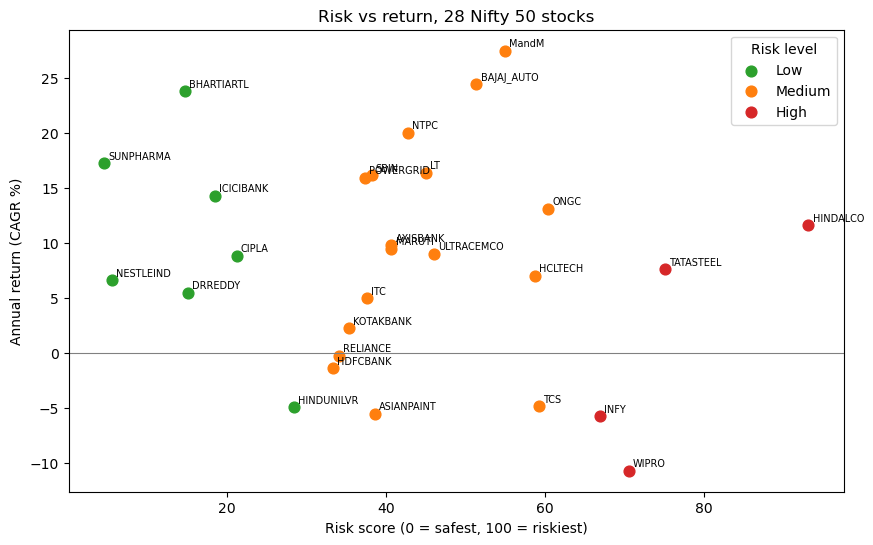

In [5]:
import matplotlib.pyplot as plt

stocks.to_csv(PROCESSED / "stock_metrics.csv")

colors = {"Low": "tab:green", "Medium": "tab:orange", "High": "tab:red"}
fig, ax = plt.subplots(figsize=(10, 6))
for level, grp in stocks.groupby("risk_level", observed=True):
    ax.scatter(grp["risk_score"], grp["cagr_%"], c=colors[level], label=level, s=60)
for sym, row in stocks.iterrows():
    ax.annotate(sym, (row["risk_score"], row["cagr_%"]), fontsize=7, xytext=(3, 3), textcoords="offset points")

ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Risk score (0 = safest, 100 = riskiest)")
ax.set_ylabel("Annual return (CAGR %)")
ax.set_title("Risk vs return, 28 Nifty 50 stocks")
ax.legend(title="Risk level")
plt.show()